In [ ]:
#Meshal Mahnoor

# Lab Task 1



**Task # 01:**

Load a grayscale image and shift the entire image 10 pixels to the left. Fill the empty space on the right with black pixels. Display the original and the shifted image side by side.

In [ ]:
image_path = "tirtir.jpg"
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageChops, ImageOps
from pathlib import Path
from scipy import ndimage
from skimage import color, morphology

%matplotlib inline

RGB shape: (678, 452, 3)
Grayscale shape: (678, 452)


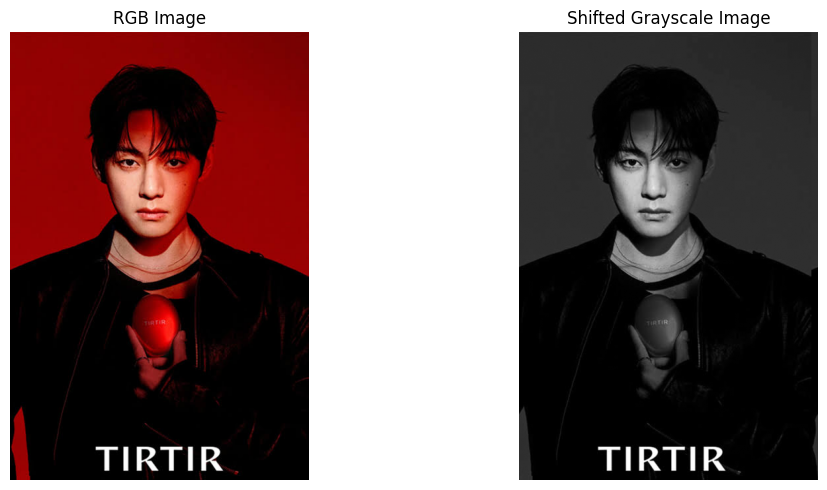

In [ ]:
image_path = "tirtir.jpg"
rgb_image = Image.open(image_path).convert("RGB")
gray_image = rgb_image.convert("L")
shifted_img = ImageChops.offset(gray_image, -10, 0)
shifted_array = np.array(shifted_img)
rgb_array = np.array(rgb_image)
gray_array = np.array(gray_image)
print("RGB shape:", rgb_array.shape)
print("Grayscale shape:", gray_array.shape)
# Display RGB and grayscale images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb_array)
axes[0].set_title("RGB Image")
axes[0].axis("off")
axes[1].imshow(shifted_array, cmap="gray")
axes[1].set_title("Shifted Grayscale Image")
axes[1].axis("off")
plt.tight_layout()
plt.show()

**Task # 02:**

Create your own 5×5 sharpening kernel (different from the one in the lab). Apply it to a slightly blurred image and compare the result with the standard 3×3 sharpening kernel. Which one looks sharper and which one introduces more noise?
*italicized text*
**Answer:** The 5X5 kernel looks sharper and also introduced more noise.

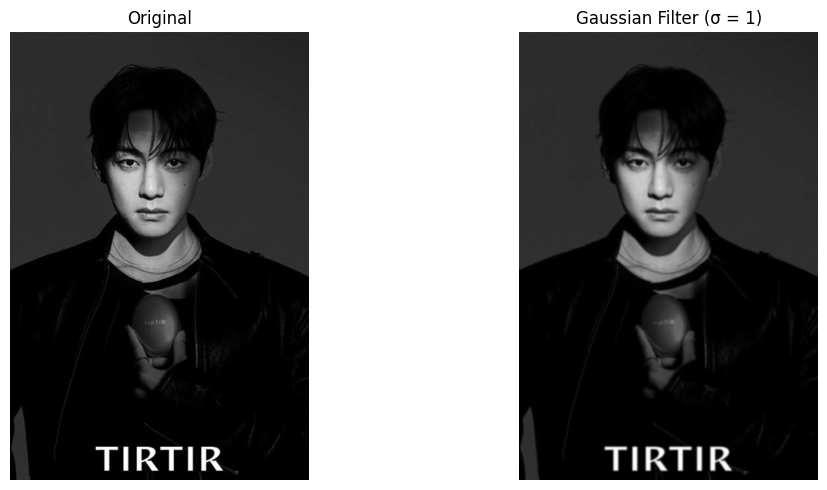

In [ ]:
#blurring the original image
gaussian_filtered = ndimage.gaussian_filter(
gray_array.astype(float),
sigma=1
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray_array, cmap="gray")
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)

plt.imshow(gaussian_filtered, cmap="gray")
plt.title("Gaussian Filter (σ = 1)")
plt.axis("off")
plt.tight_layout()
plt.show()

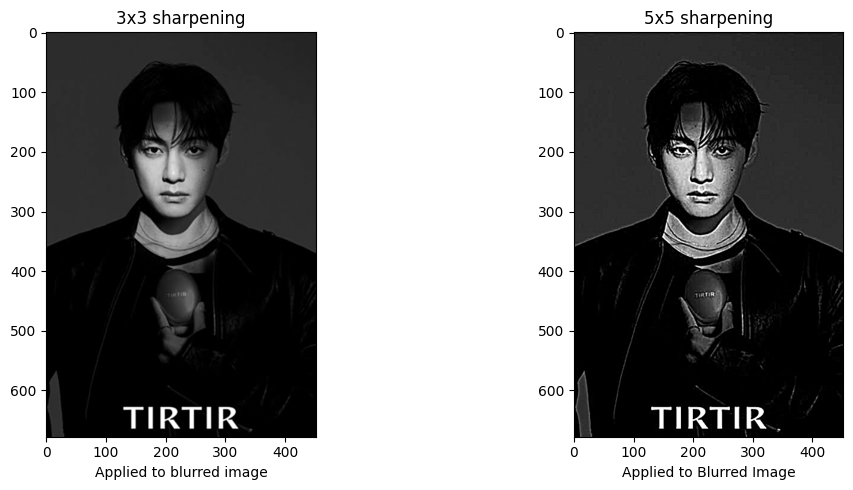

In [ ]:
# Sharpening kernel custom
sharpen_kernel = np.array([
 [ 0,  0, -1,  0,  0],
    [ 0, -1, -2, -1,  0],
    [-1, -2, 17, -2, -1],
    [ 0, -1, -2, -1,  0],
    [ 0,  0, -1,  0,  0]
], dtype=float)
sharpened = ndimage.convolve(
gaussian_filtered.astype(float),
sharpen_kernel,
mode="reflect"
)
kernel_3sharp = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
],dtype=float)
sharp3 = ndimage.convolve(
gaussian_filtered.astype(float),
kernel_3sharp,
mode="reflect"
)
kernel3= np.clip(sharp3,0,255 )
sharpened = np.clip(sharpened, 0, 255)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(kernel3, cmap="gray")
plt.title("3x3 sharpening")
plt.axis("on")
plt.xlabel("Applied to blurred image")
plt.subplot(1, 2, 2)
plt.imshow(sharpened, cmap="gray", vmin=0, vmax=255)
plt.title("5x5 sharpening")
plt.axis("on")
plt.xlabel("Applied to Blurred Image")
plt.tight_layout()
plt.show()

**Task # 03:**

Apply a strong Gaussian blur (sigma = 8) to an image, then try to recover the sharpness using the sharpening filter. Show the original, the blurred version, and the attempt to sharpen it. Comment on how well the details came back.
--------------------------------
The details inthe blurred version and sharpened version look almost identical, making it apparent that large blurring can not simply be reverted back by sharpening the image. The Gaussian Filter has permanentally lost the details in the image. There is not enough data to sharpen it back up.

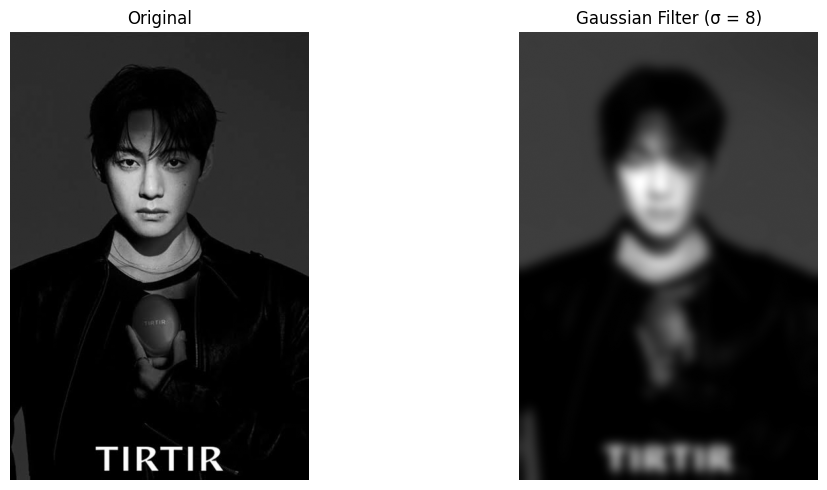

In [ ]:
#blurring the original image
gaussian_filtered_strong = ndimage.gaussian_filter(
gray_array.astype(float),
sigma=8
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray_array, cmap="gray")
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)

plt.imshow(gaussian_filtered_strong, cmap="gray")
plt.title("Gaussian Filter (σ = 8)")
plt.axis("off")
plt.tight_layout()
plt.show()

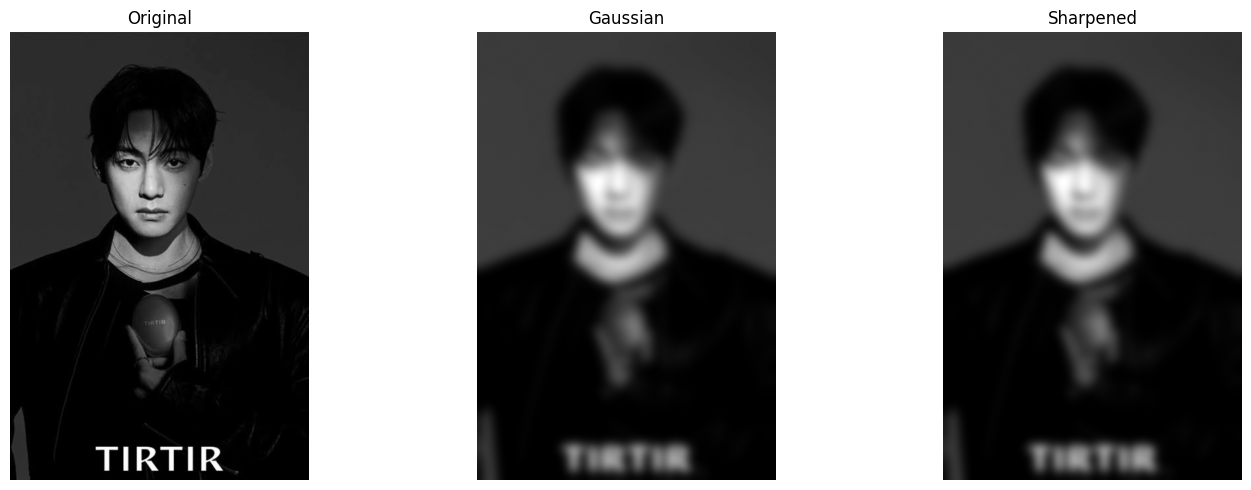

In [ ]:
#trying to recover sharpness and comparing
kernel_3sharp = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
],dtype=float)
sharp3 = ndimage.convolve(
gaussian_filtered_strong.astype(float),
kernel_3sharp,
mode="reflect"
)
kernel3= np.clip(sharp3,0,255 )
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
images = [
gray_array,
gaussian_filtered_strong,
kernel3
]
titles = [
"Original",
"Gaussian",
"Sharpened"
]
for ax, image, title in zip(axes.ravel(), images, titles):
 ax.imshow(image, cmap="gray")
 ax.set_title(title)
 ax.axis("off")
plt.tight_layout()
plt.show()

**Task # 04:**

Take a new image that has a lot of fine detail (for example a text document or a building with many windows). Convert it to grayscale and apply both a 3×3 and a 9×9 box filter. Show all three images and explain which kernel size destroys more detail.
--------------------
***The box filter 9x9 destroys the most detail. This is because the 8x9 filter produces the most smoothing/blur***

RGB shape: (1960, 1470, 3)
Grayscale shape: (1960, 1470)


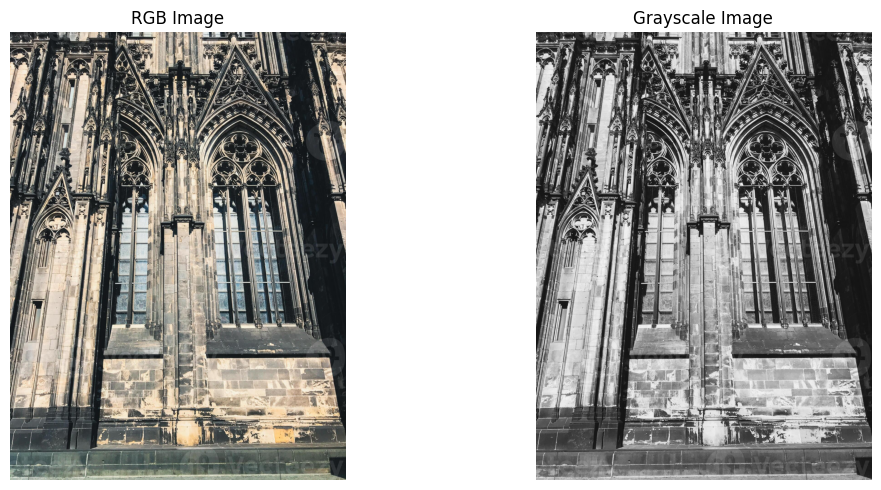

In [ ]:
image_path = "hdetail.jpg"
rgb_image = Image.open(image_path).convert("RGB")
gray_image = rgb_image.convert("L")
rgb_array = np.array(rgb_image)
gray_array = np.array(gray_image)
print("RGB shape:", rgb_array.shape)
print("Grayscale shape:", gray_array.shape)
# Display RGB and grayscale images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb_array)
axes[0].set_title("RGB Image")
axes[0].axis("off")
axes[1].imshow(gray_array, cmap="gray")
axes[1].set_title("Grayscale Image")
axes[1].axis("off")
plt.tight_layout()
plt.show()

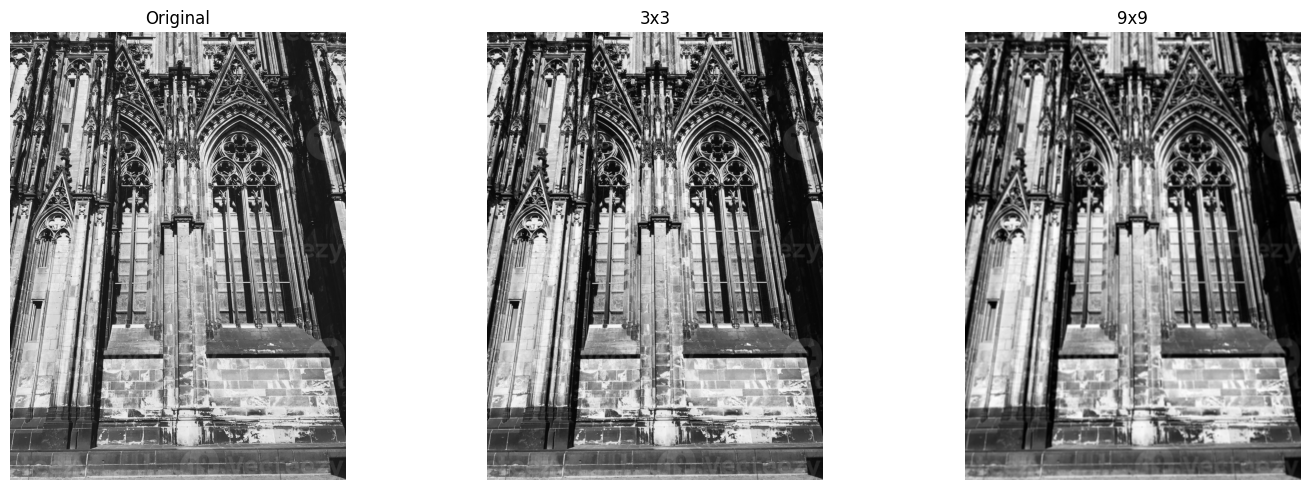

In [ ]:
#applying both box filters and comparing
box_kernel = np.ones((3, 3), dtype=float) / 9
box_filtered = ndimage.convolve(
gray_array.astype(float),
box_kernel,
mode="reflect"
)
box9_kernel = np.ones((9, 9), dtype=float) / 9
box_filtered9 = ndimage.convolve(
gray_array.astype(float),
box9_kernel,
mode="reflect"
)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
images = [
gray_array,
box_filtered,
box_filtered9
]
titles = [
"Original",
"3x3",
"9x9"
]
for ax, image, title in zip(axes.ravel(), images, titles):
 ax.imshow(image, cmap="gray")
 ax.set_title(title)
 ax.axis("off")
plt.tight_layout()
plt.show()

**Task # 05:**

Design a sequence that first removes salt and pepper noise with a median filter, then applies a gentle Gaussian filter, then computes Sobel edges on the smoothed image and finally sharpens the smoothed result, display every stage, and write a short analysis of how well the edges were preserved.

----------------------
Upon visual analysis, the edges seem well preseved, the image didnt have really sharp edged to begin with and after sharpening, the edges are even mor well defined to the point ehere you can distinguish the feature sin the picture.

RGB shape: (256, 256, 3)
Grayscale shape: (256, 256)


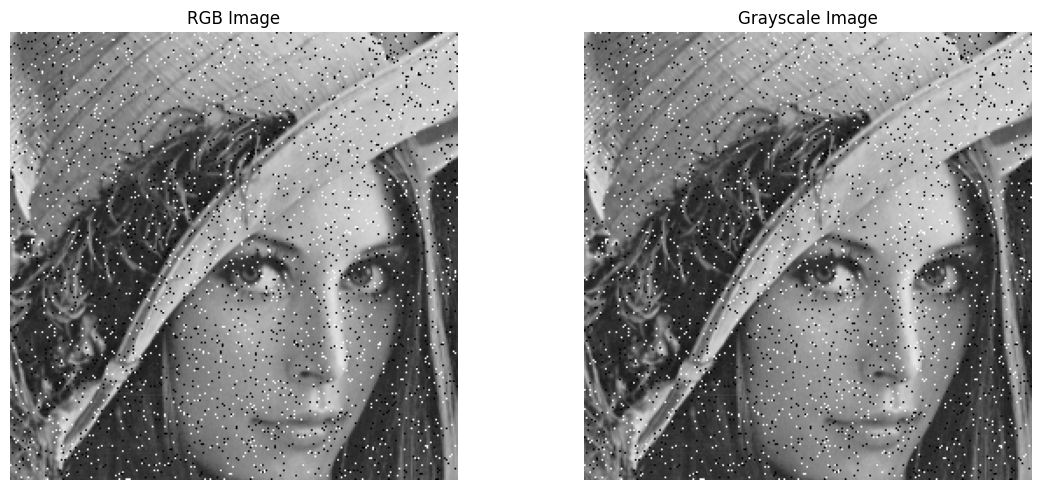

In [ ]:
#first adding the image here:
image_path = "snp_image.png"
# Load image as RGB
rgb_image = Image.open(image_path).convert("RGB")
# Convert RGB image to grayscale
gray_image = rgb_image.convert("L")
# Convert both to NumPy arrays
rgb_array = np.array(rgb_image)
gray_array = np.array(gray_image)
print("RGB shape:", rgb_array.shape)
print("Grayscale shape:", gray_array.shape)
# Display RGB and grayscale images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb_array)
axes[0].set_title("RGB Image")
axes[0].axis("off")
axes[1].imshow(gray_array, cmap="gray")
axes[1].set_title("Grayscale Image")
axes[1].axis("off")
plt.tight_layout()
plt.show()

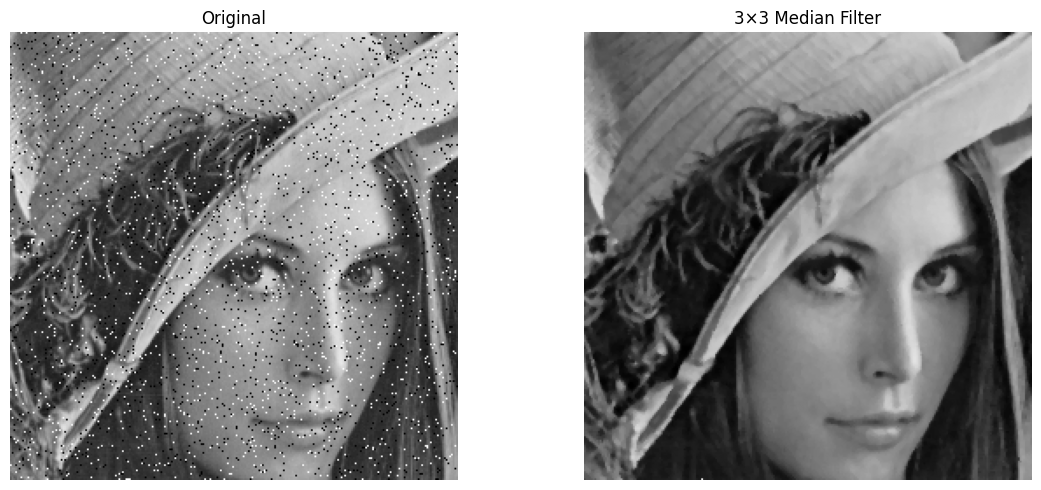

In [ ]:
# Median filtering, reducind snp noise
median_filtered = ndimage.median_filter(
gray_array,
size=3
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray_array, cmap="gray")
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(median_filtered, cmap="gray")
plt.title("3×3 Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

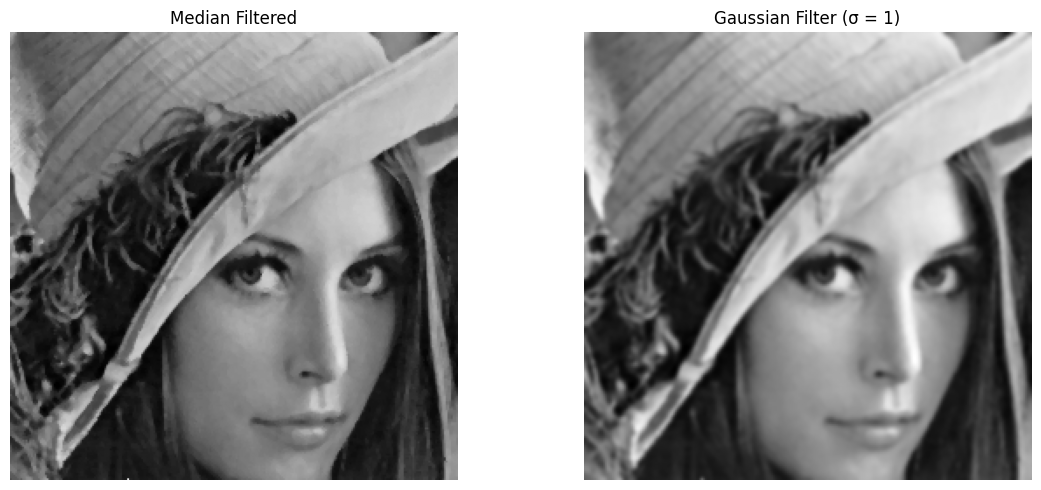

In [ ]:
#gentle gaussian filter
# Gaussian smoothing
gaussian_filtered_median = ndimage.gaussian_filter(
median_filtered.astype(float),
sigma=1
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(median_filtered, cmap="gray")
plt.title("Median Filtered")
plt.axis("off")
plt.subplot(1, 2, 2)

plt.imshow(gaussian_filtered_median, cmap="gray")
plt.title("Gaussian Filter (σ = 1)")
plt.axis("off")
plt.tight_layout()
plt.show()

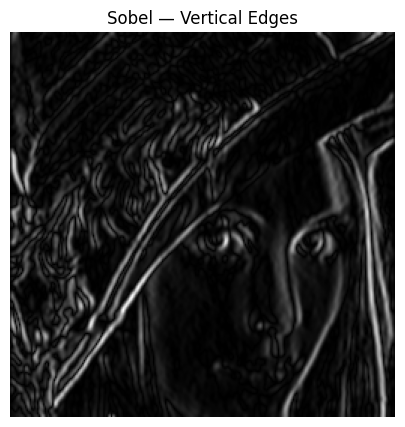

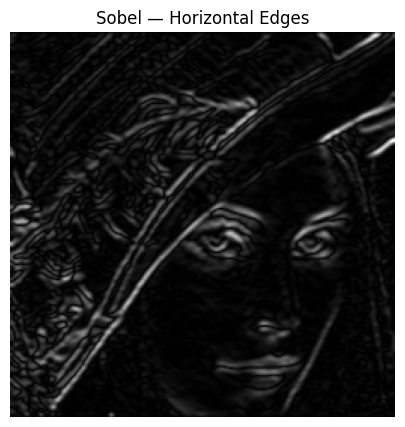

In [ ]:
#computing both sobel edges;
# Sobel vertical-edge response
sobel_vertical_kernel = np.array([
[-1, 0, 1],
[-2, 0, 2],
[-1, 0, 1]
], dtype=float)
sobel_vertical = ndimage.convolve(
gaussian_filtered_median.astype(float),
sobel_vertical_kernel,
mode="reflect"
)
plt.figure(figsize=(8, 5))
plt.imshow(np.abs(sobel_vertical), cmap="gray")
plt.title("Sobel — Vertical Edges")
plt.axis("off")
plt.show()

# Sobel horizontal-edge response
sobel_horizontal_kernel = np.array([
[-1, -2, -1],
[0, 0, 0],

[1, 2, 1]
], dtype=float)
sobel_horizontal = ndimage.convolve(
gaussian_filtered_median.astype(float),
sobel_horizontal_kernel,
mode="reflect"
)
plt.figure(figsize=(8, 5))
plt.imshow(np.abs(sobel_horizontal), cmap="gray")
plt.title("Sobel — Horizontal Edges")
plt.axis("off")
plt.show()


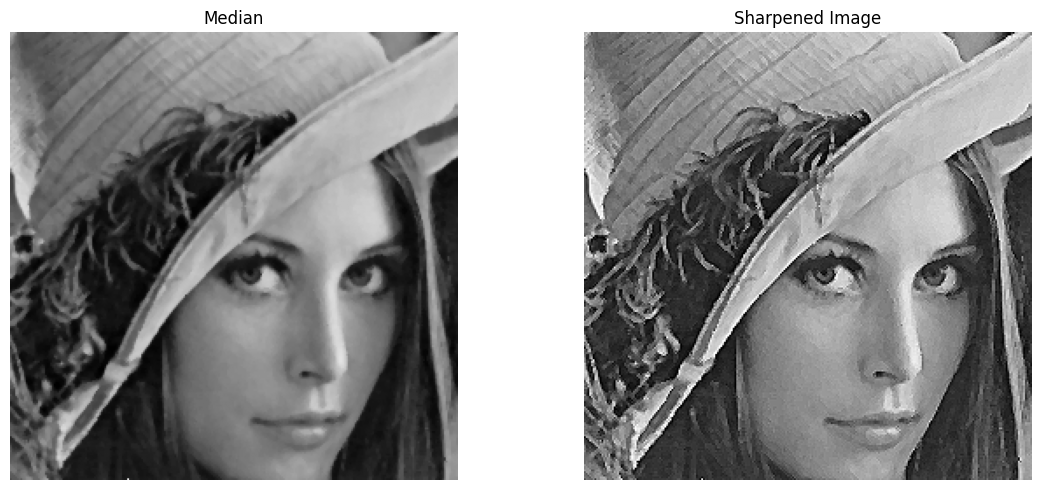

In [ ]:
#sharpening the image produced by the 3x3 median filter:
# Sharpening filter
sharpen_kernel = np.array([
[0, -1, 0],
[-1, 5, -1],
[0, -1, 0]
], dtype=float)
sharpened = ndimage.convolve(
median_filtered.astype(float),
sharpen_kernel,
mode="reflect"
)
sharpened = np.clip(sharpened, 0, 255)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(median_filtered, cmap="gray")
plt.title("Median")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(sharpened, cmap="gray", vmin=0, vmax=255)
plt.title("Sharpened Image")
plt.axis("off")
plt.tight_layout()
plt.show()

**Task # 06:**

Load a binary image (or threshold a grayscale image to make it binary). Apply erosion with a 3×3 structuring element and display the original binary image next to the eroded result.

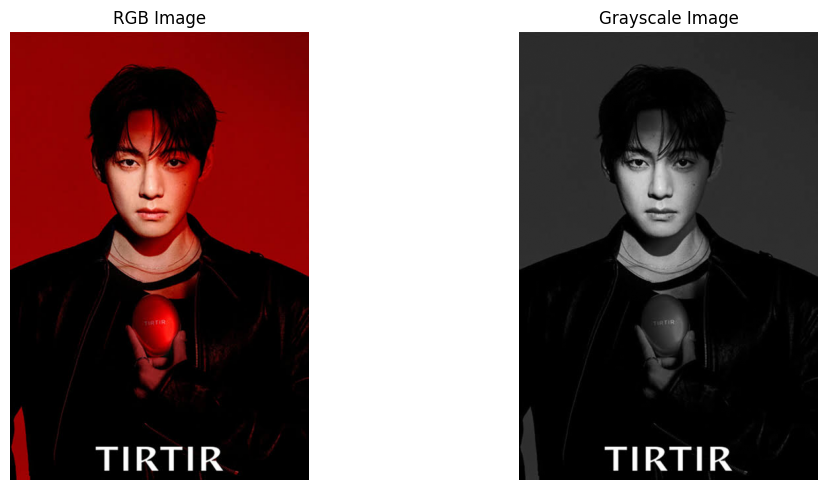

In [ ]:
#first adding the image here:
image_path = "tirtir.jpg"
# Load image as RGB
rgb_image = Image.open(image_path).convert("RGB")
# Convert RGB image to grayscale
gray_image = rgb_image.convert("L")
# Convert both to NumPy arrays
rgb_array = np.array(rgb_image)
gray_array = np.array(gray_image)
# Display RGB and grayscale images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb_array)
axes[0].set_title("RGB Image")
axes[0].axis("off")
axes[1].imshow(gray_array, cmap="gray")
axes[1].set_title("Grayscale Image")
axes[1].axis("off")
plt.tight_layout()
plt.show()

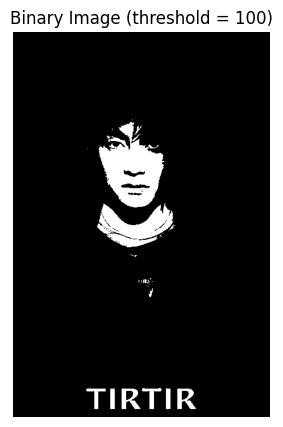

In [ ]:
# Converting the image to binary
threshold = 100
binary_image = gray_array > threshold
plt.figure(figsize=(8, 5))
plt.imshow(binary_image, cmap="gray")
plt.title(f"Binary Image (threshold = {threshold})")
plt.axis("off")
plt.show()

/tmp/ipykernel_2955/4089584733.py:2: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  structuring_element = morphology.square(3)


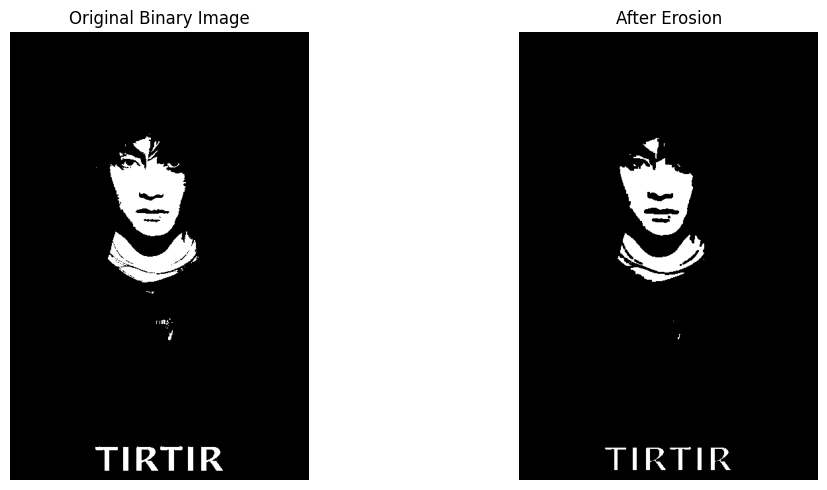

In [ ]:
#applying erosion and displaying
structuring_element = morphology.square(3)
eroded = morphology.erosion(
binary_image,
footprint=structuring_element
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(binary_image, cmap="gray")
plt.title("Original Binary Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(eroded, cmap="gray")
plt.title("After Erosion")
plt.axis("off")
plt.tight_layout()
plt.show()